# Arbeitspaket (AP) 2 – Übung: Datenbeschaffung, Datenaufbereitung & explorative Datenanalyse — Musterlösung

### Hinweis

Dies ist eine **Übungsprüfung** im Stil von AP 2 (gleicher Aufbau, gleiches Niveau, gleiches Bewertungsschema, neue Daten). Zeitbudget wie in der echten Prüfung: ca. **3 Stunden 45 Minuten**. Erlaubt: Open Book, Open Internet, **keine KI** zum Lösen der Aufgaben.

## Bewertungskriterien

**(max. erreichbare Punkte: 40)**

<table>
  <thead>
    <tr><th>Teil</th><th>Thema</th><th>Aufgaben</th><th>Punkte</th></tr>
  </thead>
  <tbody>
    <tr><td>A</td><td>Konzeptfragen: Datenaufbereitung &amp; explorative Datenanalyse</td><td>A1–A3</td><td>12</td></tr>
    <tr><td>B</td><td>Fehleranalyse Python-Code (Shop-Daten)</td><td>B1–B2</td><td>16</td></tr>
    <tr><td>C</td><td>Python-Code schreiben: Web Scraping, Datenaufbereitung &amp; EDA</td><td>C1–C3</td><td>12</td></tr>
    <tr><td><b>Total</b></td><td></td><td><b>8 Aufgaben</b></td><td><b>40</b></td></tr>
  </tbody>
</table>

### Bewertungsschema

Jede Aufgabe wird für sich und **als Ganzes** bewertet. Ihre Punktzahl steht in der Überschrift.

<table>
  <thead>
    <tr><th>Kategorie</th><th>Beschreibung</th><th>Bewertung</th><th>4 Pkt</th><th>8 Pkt</th></tr>
  </thead>
  <tbody>
    <tr><td>Korrekt</td><td>Vollständig und fachlich einwandfrei: Antwort bzw. Begründung korrekt und nachvollziehbar; bei Code-Aufgaben liefert der Python-Code das richtige Ergebnis</td><td>100%</td><td>4</td><td>8</td></tr>
    <tr><td>Minimale Mängel</td><td>Kleine Fehler (z.B. falsche Sortierung, fehlende Rundung, fehlende Achsenbeschriftung) oder Begründung ungenau bzw. unvollständig</td><td>75%</td><td>3</td><td>6</td></tr>
    <tr><td>Mittlere Mängel</td><td>Grössere Fehler (z.B. fehlende Spalten, falsche Filterung) oder Begründung fehlt bzw. ist fachlich falsch</td><td>50%</td><td>2</td><td>4</td></tr>
    <tr><td>Gravierende Mängel</td><td>Problem bzw. Ansatz erkennbar, aber Lösung oder Schlussfolgerung im Kern falsch (z.B. Problem richtig benannt, aber falsch behoben; im Code: ungeeigneter Lösungsweg wie falscher Join-Typ, falsche Tabelle oder falsche Datei)</td><td>25%</td><td>1</td><td>2</td></tr>
    <tr><td>Nicht lauffähig / nicht sinnvoll</td><td>Antwort fehlt, Code nicht lauffähig (z.B. Syntaxfehler) oder kein Bezug zur Aufgabe</td><td>0%</td><td>0</td><td>0</td></tr>
  </tbody>
</table>

Treffen mehrere Mängel zusammen, zählt der schwerste. Alternative, fachlich korrekte Lösungswege werden ebenfalls als korrekt gewertet.

## Hinweise zu den Daten

Alle Daten stammen vom **fiktiven** Schweizer Online-Shop «LaptopLand» (Laptops) und liegen **lokal** im gleichen Verzeichnis wie dieses Notebook. Für die Prüfung ist **kein Internetzugriff** auf Websites oder APIs nötig.

<table>
  <thead>
    <tr><th>Datei</th><th>Format</th><th>Inhalt</th></tr>
  </thead>
  <tbody>
    <tr><td><code>html/shop_page_1.html</code> … <code>shop_page_3.html</code></td><td>HTML</td><td>Gespeicherte Produktlisten-Seiten (3 Seiten mit Paginierung)</td></tr>
    <tr><td><code>html/product_detail.html</code></td><td>HTML</td><td>Gespeicherte Detailseite eines Laptops (technische Daten, Preisverlauf)</td></tr>
    <tr><td><code>reviews.json</code></td><td>JSON</td><td>Gespeicherte Antwort der Reviews-API: Liste mit Kundenbewertungen pro <code>product_id</code></td></tr>
    <tr><td><code>laptops_clean.csv</code></td><td>CSV</td><td>Aufbereitete Shop-Daten: Formate vereinheitlicht, Duplikate entfernt — <b>inhaltlich nicht geprüft</b></td></tr>
  </tbody>
</table>

Die Spaltenbeschreibungen finden Sie im Sheet **«Description»**, die Datenquellen im Sheet **«Data Sources»** der beiliegenden Datei `laptop_data.xlsx`. Die HTML-Dateien können Sie zur Ansicht auch im Browser oder als Text im Editor öffnen.

**Antworten auf Konzeptfragen** und **Begründungen** tragen Sie bitte direkt in die vorgesehenen Markdown-Zellen ein.

## Setup (wird nicht bewertet)

In [1]:
# Libraries
import os
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Get current working directory
print(os.getcwd())

/Users/lara/Desktop/DS_HS2026_LNW/uebungen/AP2_laptops


### Produktlisten-Seiten scrapen → `df_raw`

Der folgende Code liest die drei gespeicherten Produktlisten-Seiten mit BeautifulSoup ein. Jede Produktkarte (`<div class="product-card">`) wird zu einer Zeile im Data Frame `df_raw`. Die Werte werden **als Text** übernommen (Spalten mit Endung `_raw`) und noch nicht bereinigt. 

In [2]:
# Initialize list for the extracted rows
rows = []

# Loop over the three listing pages
for page in [1, 2, 3]:

    # Read html from file
    with open(f'html/shop_page_{page}.html', 'r', encoding='utf-8') as file:
        html_content = file.read()

    # Parse the HTML content
    soup = BeautifulSoup(html_content, 'html.parser')

    # Locate the product cards and extract values
    for card in soup.select('div.product-card'):
        row_data = [card['data-product-id'],
                    card.select('span.brand')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.model')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.storage')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.ram')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.screen')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.battery')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.price')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.availability')[0].get_text().replace('\xa0', '').strip()]
        rows.append(row_data)

# Create a DataFrame
df_raw = pd.DataFrame(rows, columns=['product_id', 'brand', 'model', 'storage_raw', 'ram_raw',
                                     'screen_raw', 'battery_raw', 'price_raw', 'availability'])

# Show dimensions and first rows
print('Number of rows and columns:', df_raw.shape)
df_raw.head()

Number of rows and columns: (138, 9)


,product_id,brand,model,storage_raw,ram_raw,screen_raw,battery_raw,price_raw,availability
0,LL-30001,HP,Pavilion Plus 14,512GB,32GB RAM,"14.0"" Display",bis 13h Akku,CHF 1'049.–,Vorbestellung
1,LL-30002,Apple,MacBook Pro 16 M4 Pro,512GB,32GB RAM,"16.2"" Display",bis 20h Akku,CHF 2'599.–,Sofort lieferbar
2,LL-30003,Apple,MacBook Pro 14 M4,1TB,24GB RAM,"14.2"" Display",bis 22h Akku,CHF 1'849.–,Vorbestellung
3,LL-30004,Dell,Inspiron 15,256GB,8GB RAM,"15.6"" Display",bis 8h Akku,CHF 499.–,Vorbestellung
4,LL-30005,Asus,ROG Strix G16,512GB,16GB RAM,"16.0"" Display",bis 3h Akku,CHF 1'899.–,Vorbestellung


### Aufbereitete Shop-Daten laden → `df_clean`

In [3]:
# Import data from csv to pandas dataframe named 'df_clean'
df_clean = pd.read_csv('laptops_clean.csv')

# Show dimensions and first rows
print('Number of rows and columns:', df_clean.shape)
df_clean.head()

Number of rows and columns: (132, 10)


,product_id,brand,model,storage_gb,ram_gb,color,screen_inch,battery_h,price_chf,availability
0,LL-30001,HP,Pavilion Plus 14,512,32,Silber,14.0,NaN,1049.0,Vorbestellung
1,LL-30002,Apple,MacBook Pro 16 M4 Pro,512,32,Space Schwarz,16.2,20.0,2599.0,Sofort lieferbar
2,LL-30003,Apple,MacBook Pro 14 M4,1024,24,Space Schwarz,14.2,22.0,1849.0,Vorbestellung
3,LL-30004,Dell,Inspiron 15,256,8,Schwarz,15.6,8.0,499.0,Vorbestellung
4,LL-30005,Asus,ROG Strix G16,512,16,Schwarz,16.0,3.0,1899.0,Vorbestellung


> **Hinweis:** Alle Aufgaben sind voneinander unabhängig. Verändern Sie `df_raw` und `df_clean` bitte nicht direkt, sondern arbeiten Sie in jeder Aufgabe mit einem eigenen Data Frame (z.B. `df_B1`, `df_C2`).

---

<div style="background-color:#2E4057; color:white; padding:16px 24px; border-radius:6px; font-size:18px; margin-top:8px;">
&#9654;&nbsp; <strong>Ab hier beginnt die bewertete Übungsprüfung — 40 Punkte</strong><br>
<span style="font-size:15px; font-weight:normal;">Tragen Sie Ihre Antworten direkt in die vorgesehenen Zellen ein und führen Sie alle Code-Zellen aus.</span>
</div>

---
## Teil A – Konzeptfragen (12 Punkte)

*Antworten ohne Bezug zu den Shop-Daten von «LaptopLand» werden nicht gewertet.*

### A1 (4 Punkte)

In `laptops_clean.csv` fehlt bei 7 der 132 Laptops die Akkulaufzeit (`battery_h`). Laut IT-Abteilung ist beim nächtlichen Import der Herstellerdaten bei einzelnen, zufällig betroffenen Datensätzen die Übertragung abgebrochen – unabhängig von Marke, Modell oder Akkulaufzeit.

a) Um welchen Mechanismus fehlender Werte handelt es sich (MCAR, MAR oder MNAR)? Begründen Sie.

b) Eine Analystin entfernt diese 7 Laptops mit `dropna()` und berichtet anschliessend die durchschnittliche Akkulaufzeit des Sortiments. Welchen Effekt hat das Entfernen auf das Ergebnis?

**Ihre Antwort:**

a) **MCAR (missing completely at random):** Ob die Akkulaufzeit fehlt, hängt weder von der Akkulaufzeit selbst noch von anderen Variablen (Marke, Modell) ab – die Datensätze sind durch einen zufälligen Importfehler betroffen.

b) Bei MCAR ist das Entfernen **unproblematisch**: Der Durchschnitt wird **nicht verzerrt**, er beruht nur auf etwas weniger Beobachtungen (125 statt 132) und ist dadurch etwas weniger genau.

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 10–11 (Entfernen fehlender Werte; MCAR: «can be removed»).*

### A2 (4 Punkte)

Für die Spalte `price_chf` in `laptops_clean.csv` liefert pandas folgendes Ergebnis:

```
df_clean['price_chf'].describe()
count      127.00
mean      1817.59
std       5404.81
min        259.00
25%        924.00
50%       1299.00
75%       1724.00
max      61900.00
```

a) Berechnen Sie mit der **1.5 × IQR-Regel** (wie beim Boxplot) die untere und die obere Grenze, ab der ein Preis als Ausreisser gilt.

b) Oberhalb der oberen Grenze liegen zwei Laptops: ein *MacBook Pro 16 M4 Pro* mit 2 TB für CHF 3'399 und ein *Lenovo IdeaPad Slim 3* für CHF 61'900. Wie gehen Sie mit diesen beiden Werten um? Begründen Sie.

**Ihre Antwort:**

a) IQR = Q3 − Q1 = 1724 − 924 = **800**.
Untere Grenze: 924 − 1.5 · 800 = **−276** (praktisch keine Ausreisser nach unten).
Obere Grenze: 1724 + 1.5 · 800 = **2924**.

b) Ausreisser werden geprüft und **nur entfernt, wenn sie Fehler sind**:
- **MacBook Pro 16 mit 2 TB für CHF 3'399:** plausibel (teuerstes Modell mit grösstem Speicher) → ein **echter Ausreisser**, bleibt in den Daten.
- **IdeaPad Slim 3 für CHF 61'900:** gleiche Modelle kosten CHF 399–1'149 → **Erfassungsfehler** (wahrscheinlich Preis in Rappen statt Franken, korrekt wäre CHF 619) → entfernen bzw. korrigieren.

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 5, S. 29 (Boxplot, Whiskers bei Q1 − 1.5·IQR und Q3 + 1.5·IQR); Folien Woche 4 Teil II, S. 13 (Ausreisser vs. Messfehler: «only removed if they are errors»).*

### A3 (4 Punkte)

Ein Kollege möchte wissen, ob Laptops mit mehr Speicherplatz teurer sind. Er berechnet die Korrelation zwischen `storage_gb` (Werte 256, 512, 1024, 2048) und `price_chf`:

```
df_clean[['storage_gb', 'price_chf']].corr()     # Ergebnis: r = -0.01
```

Er folgert: *«Der Speicherplatz hat keinen Einfluss auf den Preis.»*

Nennen und begründen Sie **zwei** fachliche Einwände gegen diese Vorgehensweise bzw. Schlussfolgerung.

**Ihre Antwort:**

1. **Ausreisser:** Der Erfassungsfehler von CHF 61'900 (vgl. A2) verfälscht die Pearson-Korrelation stark – ohne ihn ist r = 0.41.
2. **Keine Grafik:** Kennzahlen allein können irreführend sein (Anscombe-Quartett). Zuerst sollte man einen Scatter Plot bzw. – weil `storage_gb` nur vier Stufen hat – einen **Boxplot des Preises pro Speichergrösse** erstellen.
3. **Korrelation ≠ Kausalität:** Eine Korrelation sagt nichts über Ursache und Wirkung («Einfluss») aus; teure Modelle haben z.B. oft auch mehr Speicher *und* bessere Prozessoren.

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 5, S. 12 (Anscombe-Quartett), S. 25 und S. 41 (Korrelation und Kausalität); Folien Woche 4 Teil II, S. 13 (Ausreisser).*

---
## Teil B – Fehleranalyse Python-Code (16 Punkte)

*Jeder Code läuft fehlerfrei durch, liefert aber ein falsches oder irreführendes Ergebnis. Die tatsächlichen Ergebnisse sind angegeben.*

### B1 (8 Punkte)

**Ziel:** Kennzahlen für das Shop-Sortiment aus den gescrapten Rohdaten `df_raw`: Anzahl Laptops, Anzahl Laptops ohne Preisangabe, Median-Preis in CHF und Median-Speicherplatz in GB.

```python
# Select columns for the analysis
df_B1 = df_raw[['product_id', 'brand', 'model', 'storage_raw', 'price_raw']]

# Extract numerical values from storage_raw
storage = []
for i in df_B1['storage_raw']:
    d1 = re.findall(r"\d+", i)
    storage.append(int(d1[0]))

# Extract numerical values from price_raw
price = []
for i in df_B1['price_raw']:
    d1 = re.findall(r"\d+", i)
    try:
        d2 = int(''.join(d1))
    except:
        d2 = None
    price.append(d2)

# Save as new variables in the pandas data frame
df_B1['storage_gb'] = pd.Series(storage, dtype="Int64")
df_B1['price_chf'] = pd.Series(price, dtype="Int64")

# Show key figures
print('Anzahl Laptops:           ', df_B1.shape[0])
print('Anzahl ohne Preisangabe:  ', df_B1['price_chf'].isnull().sum())
print('Median-Preis (CHF):       ', df_B1['price_chf'].median())
print('Median-Speicher (GB):     ', df_B1['storage_gb'].median())
```

Tatsächliches Ergebnis:

```
Anzahl Laptops:            138
Anzahl ohne Preisangabe:   5
Median-Preis (CHF):        1249.0
Median-Speicher (GB):      256.0
```

Der Shop gibt auf jeder Seite an, dass er **132 Artikel** führt. Beispiele für Werte in `storage_raw`: `256GB`, `512GB`, `1TB`, `2TB`. Beispiele für Werte in `price_raw`: `CHF 1'049.–`, `CHF 499.–`, `Preis auf Anfrage`.

**Aufgabe:** Schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben), sodass die Kennzahlen stimmen. Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

1. **Duplikate entfernen:** Es gibt Duplikate (138 statt 132 Laptops), weil sich die Seiten überlappen (die letzten Karten einer Seite erscheinen auf der nächsten Seite erneut). `drop_duplicates()` entfernt sie, `reset_index(drop=True)` nummeriert den Index neu – sonst passen die neuen Spalten (`pd.Series`) nicht mehr zu den Zeilen.
2. **TB in GB umrechnen:** Bei `1TB` bzw. `2TB` liefert `re.findall` nur `1` bzw. `2`. Diese Laptops erscheinen dadurch als die mit dem *kleinsten* Speicher. Korrektur: Enthält der Text `TB`, wird der Wert mit 1024 multipliziert.

Die Preis-Extraktion mit `''.join(d1)` war bereits korrekt.

Ergebnis: **132** Laptops, **5** ohne Preisangabe, Median-Preis **CHF 1299.0**, Median-Speicher **512 GB**.

**Korrigierter Code:**

In [4]:
# Select columns for the analysis, remove duplicated values and reset the index
df_B1 = df_raw[['product_id', 'brand', 'model', 'storage_raw', 'price_raw']].drop_duplicates().reset_index(drop=True)

# Extract numerical values from storage_raw (convert TB to GB)
storage = []
for i in df_B1['storage_raw']:
    d1 = re.findall(r"\d+", i)
    d2 = int(d1[0])
    if 'TB' in i:
        d2 = d2 * 1024
    storage.append(d2)

# Extract numerical values from price_raw
price = []
for i in df_B1['price_raw']:
    d1 = re.findall(r"\d+", i)
    try:
        d2 = int(''.join(d1))
    except:
        d2 = None
    price.append(d2)

# Save as new variables in the pandas data frame
df_B1['storage_gb'] = pd.Series(storage, dtype="Int64")
df_B1['price_chf'] = pd.Series(price, dtype="Int64")

# Show key figures
print('Anzahl Laptops:           ', df_B1.shape[0])
print('Anzahl ohne Preisangabe:  ', df_B1['price_chf'].isnull().sum())
print('Median-Preis (CHF):       ', df_B1['price_chf'].median())
print('Median-Speicher (GB):     ', df_B1['storage_gb'].median())

Anzahl Laptops:            132
Anzahl ohne Preisangabe:   5
Median-Preis (CHF):        1299.0
Median-Speicher (GB):      512.0


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Übung `advanced_data_preparation_car_data_solution.ipynb` (Extract numerical values mit `re.findall`; Count and remove duplicated values mit `drop_duplicates()` und `reset_index(drop=True)`); Folien Woche 4 Teil II, S. 12 (Duplikate) und S. 17 (Zahlen mit Regex extrahieren). Statt 1024 wird auch 1000 als korrekt gewertet (der Median bleibt 512).*

### B2 (8 Punkte)

**Ziel:** Herausfinden, welche Marke im Sortiment am teuersten ist (auf Basis von `df_clean`).

```python
# Select columns for the analysis
df_B2 = df_clean[['brand', 'price_chf']]

# Price per brand
df_B2.groupby(['brand']).mean().round(2).sort_values(by='price_chf', ascending=False)
```

Tatsächliches Ergebnis:

```
           price_chf
brand
Lenovo       2845.97
Apple        1854.42
Samsung      1555.67
Microsoft    1475.67
Dell         1419.62
...
```

Der Einkaufsleiter ist skeptisch: *«Lenovo verkauft bei uns vor allem günstige IdeaPads – das kann nicht stimmen.»*

**Aufgabe:** Untersuchen Sie die Daten mit geeigneten EDA-Methoden, finden Sie die Ursache für das irreführende Ergebnis und schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben). Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

`describe()`, Boxplot und Sortierung zeigen einen Ausreisser: Ein Lenovo IdeaPad Slim 3 kostet CHF 61'900 – dasselbe Modell kostet sonst CHF 399–1'149. Das ist ein Erfassungsfehler (Preis in Rappen statt Franken).

1. **Ausreisser entfernen:** Er ist ein Fehler und darf deshalb entfernt werden (alternativ korrigieren: 61900 / 100 = 619).
2. **Median statt Mittelwert:** Die Preise sind rechtsschief; der Median wird von Ausreissern kaum beeinflusst.

Ergebnis: Lenovo fällt auf den zweitletzten Platz (Median CHF 1049). Am teuersten ist **Apple** (Median CHF 1824; auch mit dem Mittelwert ohne Ausreisser: CHF 1854.42).

**Korrigierter Code:**

count      127.00
mean      1817.59
std       5404.81
min        259.00
25%        924.00
50%       1299.00
75%       1724.00
max      61900.00
Name: price_chf, dtype: float64 



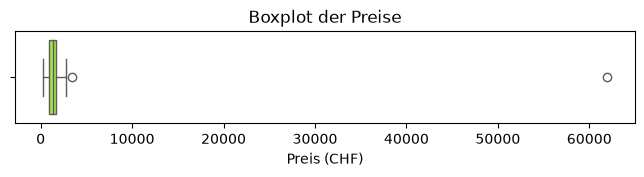

     brand                  model  storage_gb  price_chf
5   Lenovo         IdeaPad Slim 3         512    61900.0
61   Apple  MacBook Pro 16 M4 Pro        2048     3399.0
7    Apple  MacBook Pro 16 M4 Pro        1024     2769.0 

              model  storage_gb  price_chf
5    IdeaPad Slim 3         512    61900.0
18   IdeaPad Slim 3        2048     1149.0
21   IdeaPad Slim 3         256      399.0
51   IdeaPad Slim 3        1024      749.0
53   IdeaPad Slim 3        1024      749.0
69   IdeaPad Slim 3         512      549.0
74   IdeaPad Slim 3         256      449.0
82   IdeaPad Slim 3         256      449.0
109  IdeaPad Slim 3        1024      749.0
125  IdeaPad Slim 3        1024      659.0
131  IdeaPad Slim 3         256      599.0 



,price_chf
brand,
Apple,1824.0
Samsung,1649.0
Dell,1589.0
Microsoft,1474.0
HP,1319.0
Asus,1099.0
Lenovo,1049.0
Acer,849.0


In [5]:
# Statistical measures
print(df_clean['price_chf'].describe().round(2), '\n')

# Boxplot (seaborn)
plt.figure(figsize=(8,1.2))
sns.boxplot(x=df_clean['price_chf'], color="greenyellow")
plt.title('Boxplot der Preise', fontsize=12)
plt.xlabel('Preis (CHF)')
plt.show()

# Most expensive laptops
print(df_clean[['brand', 'model', 'storage_gb', 'price_chf']].sort_values(by='price_chf', ascending=False).head(3), '\n')

# Same model for comparison
print(df_clean.loc[df_clean['model'] == 'IdeaPad Slim 3', ['model', 'storage_gb', 'price_chf']], '\n')

# Remove the data entry error (price in Rappen instead of CHF)
df_B2 = df_clean.loc[(df_clean['price_chf'] != 61900)]

# Median price per brand
df_B2[['brand', 'price_chf']].groupby(['brand']).median().sort_values(by='price_chf', ascending=False)

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bewertung: Entscheidend ist, dass der Erfassungsfehler erkannt und begründet behandelt wird. Mittelwert oder Median nach dem Entfernen bzw. Korrigieren gelten beide als korrekt.*
>
> *Bezug: Folien Woche 4 Teil II, S. 13 und S. 47–49 (`.sort_values()`, `.groupby()`); Folien Woche 5, S. 14 (Mittelwert/Median), S. 29–30 (Boxplot); Übung `exploratory_data_analysis_car_data_solution.ipynb` (`describe()`, Boxplot, Filtern mit `.loc[...]`).*

---
## Teil C – Python-Code schreiben (12 Punkte)

Schreiben Sie Python-Code und begründen Sie Ihre Vorgehensweise jeweils in 1–2 Sätzen. Worauf die Begründung eingehen soll, steht bei der Aufgabe.

### C1 (4 Punkte)

Die Datei `html/product_detail.html` enthält die Detailseite des Dell XPS 13. In der Code-Zelle ist bereits ein Gerüst vorgegeben, das die HTML-Datei einliest und eine Tabelle Zeile für Zeile in den Data Frame `df_C1` mit den Spalten `datum` und `preis` überführt.

Ergänzen Sie die beiden mit `# TODO` markierten Stellen:

1. Wählen Sie die Tabelle **«Preisverlauf»** aus.
2. Entfernen Sie die Kopfzeile der Tabelle («Datum», «Preis») — sie enthält **keine** Daten und darf im Ergebnis nicht als leere Zeile vorkommen.

Begründen Sie, wie Sie die richtige Tabelle auswählen und die Kopfzeile entfernen.

*Tipp: Öffnen Sie die HTML-Datei im Editor und sehen Sie sich `df_C1` vor dem Entfernen der Kopfzeile an.*

**Begründung der Vorgehensweise:**

«Preisverlauf» ist die **zweite** Tabelle der Seite (nach «Technische Daten»), daher `find_all('table')[1]` – robuster ist die Auswahl über die Klasse: `soup.find('table', class_='price-history')`. Die Kopfzeile besteht nur aus `<th>`-Zellen und hat keine `<td>`-Zellen; sie ergibt deshalb eine leere Zeile (`None`), die `dropna()` entfernt.

**Python-Code:**

In [6]:
# Read html from file
with open('html/product_detail.html', 'r', encoding='utf-8') as file:
    html_content = file.read()

# Parse the HTML content
soup = BeautifulSoup(html_content, 'html.parser')

# Locate the table «Preisverlauf» (second table on the page; alternative: soup.find('table', class_='price-history'))
table = soup.find_all('table')[1]

# Extract table rows
rows = []
for row in table.find_all('tr'):
    rows.append([cell.get_text().strip() for cell in row.find_all('td')])

# Create a DataFrame
df_C1 = pd.DataFrame(rows, columns=['datum', 'preis'])

# Remove the header row (it contains no data)
df_C1 = df_C1.dropna().reset_index(drop=True)

# Show the result
df_C1

,datum,preis
0,01.10.2025,CHF 1'499.–
1,01.12.2025,CHF 1'399.–
2,01.02.2026,CHF 1'399.–
3,01.04.2026,CHF 1'349.–
4,01.06.2026,CHF 1'399.–
5,01.08.2026,CHF 1'279.–
6,01.10.2026,CHF 1'229.–


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Übung `skipass_data.ipynb` (Read html from file, `find('table')`, `find_all('tr')`, `find_all('td')`, `get_text()`); Übung `advanced_data_preparation_car_data_solution.ipynb` (`dropna()`, `reset_index(drop=True)`).*

### C2 (4 Punkte)

Teilen Sie die Laptops in `df_clean` anhand von `battery_h` mit `pd.qcut()` in **drei ungefähr gleich grosse Klassen** mit den Labels `kurz`, `mittel` und `lang` ein (neue Spalte `akku_klasse`).

Erstellen Sie anschliessend mit `pd.crosstab()` eine Kontingenztabelle mit der Anzahl Laptops pro Marke (`brand`, Zeilen) und Akku-Klasse (`akku_klasse`, Spalten). Begründen Sie, wie `pd.qcut()` die Klassengrenzen bestimmt und was mit den Laptops ohne Akkulaufzeit geschieht.

**Begründung der Vorgehensweise:**

`pd.qcut()` setzt die Grenzen über **Quantile** (hier Terzile), sodass jede Klasse etwa gleich viele Laptops enthält. Weil viele Laptops die gleiche Akkulaufzeit haben, sind die Klassen nur *ungefähr* gleich gross. Laptops ohne Akkulaufzeit (NaN) erhalten keine Klasse und werden in der Kreuztabelle nicht gezählt (125 statt 132).

**Python-Code:**

In [7]:
# Select columns for the analysis
df_C2 = df_clean[['brand', 'battery_h']]

# Discretization of the variable 'battery_h' into 3 bins (note the 'qcut' function)
df_C2['akku_klasse'] = pd.qcut(df_C2['battery_h'],
                               q=3,
                               labels=['kurz', 'mittel', 'lang'])

# Contingency table
pd.crosstab(df_C2['brand'], df_C2['akku_klasse'])

akku_klasse,kurz,mittel,lang
brand,,,
Acer,10,3,0
Apple,0,0,23
Asus,8,3,1
Dell,2,11,2
HP,9,11,0
Lenovo,16,17,1
Microsoft,0,0,5
Samsung,0,1,2


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Übung `advanced_data_preparation_car_data_solution.ipynb` (Discretization mit `pd.qcut` und Labels); Übung `exploratory_data_analysis_car_data_solution.ipynb` (`pd.crosstab`); Folien Woche 4 Teil II, S. 26–27 (Diskretisierung) und Woche 5, S. 21–22 (Kontingenztabelle).*

### C3 (4 Punkte)

Lesen Sie die Kundenbewertungen aus `reviews.json` in einen Data Frame ein und verbinden Sie ihn mit `.merge()` über `product_id` mit `df_clean`. Berechnen Sie die **Spearman-Rangkorrelation** zwischen `battery_h` und `avg_score` (gerundet auf 2 Dezimalstellen) und erstellen Sie ein Streudiagramm (Scatter Plot) mit beschrifteten Achsen.

Begründen Sie, welche Laptops nach dem `.merge()` im Data Frame enthalten sind, und interpretieren Sie das Ergebnis in 1–2 Sätzen.

**Begründung der Vorgehensweise:**

`.merge()` behält standardmässig (inner join) nur Laptops, die in **beiden** Data Frames vorkommen – also die 107 Laptops mit Bewertung (Laptops ohne Bewertung und Bewertungen nicht mehr geführter Laptops fallen weg). Davon haben 5 keine Akkulaufzeit; die Korrelation beruht daher auf 102 Laptops.

**Interpretation:** Mit 0.76 besteht ein starker positiver Zusammenhang: Laptops mit längerer Akkulaufzeit werden tendenziell besser bewertet. Das ist kein Beleg für Ursache und Wirkung.

**Python-Code:**

Number of rows: 107
Rows with battery_h: 102 

           battery_h  avg_score
battery_h       1.00       0.76
avg_score       0.76       1.00


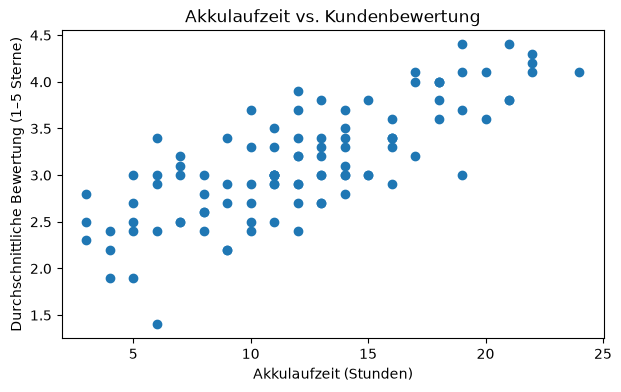

In [8]:
# Read data to a data frame using the pandas library
df_reviews = pd.read_json('reviews.json')

# Join the reviews to the shop data using .merge()
df_C3 = df_clean.merge(df_reviews, on='product_id')
print('Number of rows:', df_C3.shape[0])
print('Rows with battery_h:', df_C3['battery_h'].notna().sum(), '\n')

# Spearman rank correlation
print(df_C3[['battery_h', 'avg_score']].corr(method='spearman').round(2))

# Scatterplot of battery life and customer rating
plt.figure(figsize=(7,4))
plt.scatter(df_C3['battery_h'], df_C3['avg_score'])
plt.title('Akkulaufzeit vs. Kundenbewertung', fontsize=12)
plt.xlabel('Akkulaufzeit (Stunden)')
plt.ylabel('Durchschnittliche Bewertung (1–5 Sterne)')
plt.show()

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Übung `input_output_and_formatting_Python.ipynb` (`pd.read_json`); Übung `advanced_data_preparation_car_data_solution.ipynb` (`.merge(..., on=...)`); Übung `exploratory_data_analysis_apartments_data.ipynb` (`.corr()`, Scatterplot); Folien Woche 5, S. 25–26 (Korrelation, Tipp `method='spearman'`), S. 37 (Scatter Plot) und S. 41 (Korrelation ≠ Kausalität).*

---
### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [9]:
# Libraries
import os, platform, socket
from platform import python_version
from datetime import datetime

# Print system information
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('-----------------------------------')


-----------------------------------
POSIX
Darwin | 25.5.0
Datetime: 2026-11-05 19:06:19
Python Version: 3.14.4
-----------------------------------
